# XG-X 測定結果レポート

In [140]:
# ---------------------------------------------
#  Import
# ---------------------------------------------
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# 日本語対応
plt.rcParams["font.family"] = "Yu Gothic"

In [141]:
# ---------------------------------------------
#  Settings
# ---------------------------------------------
DB_FILE = "data/tp-link_b90c_xg_xgx_inspection.db"

START_DATETIME = "2026-10-21 10:20:00"
END_DATETIME = "2026-10-21 10:30:00"

In [ ]:
display(
    Markdown(
        f"### 対象期間：{START_DATETIME} ～ {END_DATETIME}"
        "\n---"
    )
)

### 対象期間：2026-10-21 10:20:00 ～ 2026-10-21 10:30:00

In [143]:
# ---------------------------------------------
#  Load database
# ---------------------------------------------
with sqlite3.connect(DB_FILE) as conn:
    df = pd.read_sql_query("SELECT * FROM result", conn)

df["measured_at"] = pd.to_datetime(df["measured_at"])

# display(df.head())

In [144]:
# ---------------------------------------------
#  Summary
# ---------------------------------------------
df_summary = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME)
]

total_count = len(df_summary)
ok_count = (df_summary["jg_all"] == 0).sum()
ng_count = (df_summary["jg_all"] == 1).sum()

ng_items = [
    ("深キズ円周", "fukakizu_circ_jg"),
    ("深キズXY", "fukakizu_xy_jg"),
    ("浅キズ円周", "asakizu_circ_jg"),
    ("浅キズXY", "asakizu_xy_jg"),
    ("面取り径", "mentorikei_jg"),
    ("芯ズレ", "shinzure_jg"),
]

ok_ratio = ok_count / total_count * 100 if total_count else 0
ng_ratio = ng_count / total_count * 100 if total_count else 0

summary_text = f"""
## サマリー

### 1. 全体結果

- 検査総数：**{total_count}**（構成比：**100.0%**）
- OK数：**{ok_count}**（構成比：**{ok_ratio:.1f}%**）
- NG数：**{ng_count}**（構成比：**{ng_ratio:.1f}%**）

### 2. NG内訳

"""

for label, column in ng_items:
    count = (df_summary[column] == 1).sum()
    ratio = count / total_count * 100 if total_count else 0

    summary_text += (
        f"- {label} NG数：**{count}** "
        f"（構成比：**{ratio:.1f}%**）\n"
    )

display(Markdown(summary_text))


## サマリー

### 1. 全体結果

- 検査総数：**50**（構成比：**100.0%**）
- OK数：**43**（構成比：**86.0%**）
- NG数：**7**（構成比：**14.0%**）

### 2. NG内訳

- 深キズ円周 NG数：**5** （構成比：**10.0%**）
- 深キズXY NG数：**0** （構成比：**0.0%**）
- 浅キズ円周 NG数：**3** （構成比：**6.0%**）
- 浅キズXY NG数：**0** （構成比：**0.0%**）
- 面取り径 NG数：**0** （構成比：**0.0%**）
- 芯ズレ NG数：**0** （構成比：**0.0%**）


In [145]:
# ---------------------------------------------
#  Functions
# ---------------------------------------------
def create_level_volume_graph(df, column_prefix, display_label):
    level_column = f"{column_prefix}_level"
    volume_column = f"{column_prefix}_volume"
    jg_column = f"{column_prefix}_jg"

    x = range(len(df))

    fig, (ax1, ax2) = plt.subplots(
        2,
        1,
        figsize=(10, 5),
    )

    # Level
    ax1.plot(
        x,
        df[level_column],
        color="black",
        linewidth=0.5,
        marker="o",
        markersize=4,
    )

    ax1.set_ylabel("傷レベル")
    ax1.set_title(f"{display_label} - 傷レベル")
    ax1.tick_params(axis="x", bottom=False, labelbottom=False)

    # Volume
    ax2.plot(
        x,
        df[volume_column],
        color="black",
        linewidth=0.5,
    )

    colors = df[jg_column].map({
        0: "green",
        1: "red",
    })

    ax2.scatter(
        x,
        df[volume_column],
        c=colors,
        s=20,
    )

    first_datetime = df["measured_at"].iloc[0]
    last_datetime = df["measured_at"].iloc[-1]

    ax2.set_xticks(
        [0, len(df) - 1],
        [
            first_datetime.strftime("%m/%d %H:%M:%S"),
            last_datetime.strftime("%m/%d %H:%M:%S"),
        ],
    )

    ax2.set_xlabel("測定日時")
    ax2.set_ylabel("総傷量")
    ax2.set_title(f"{display_label} - 総傷量")

    plt.tight_layout()
    plt.show()

---
### 1. 深キズ円周 傷レベル＆総傷量

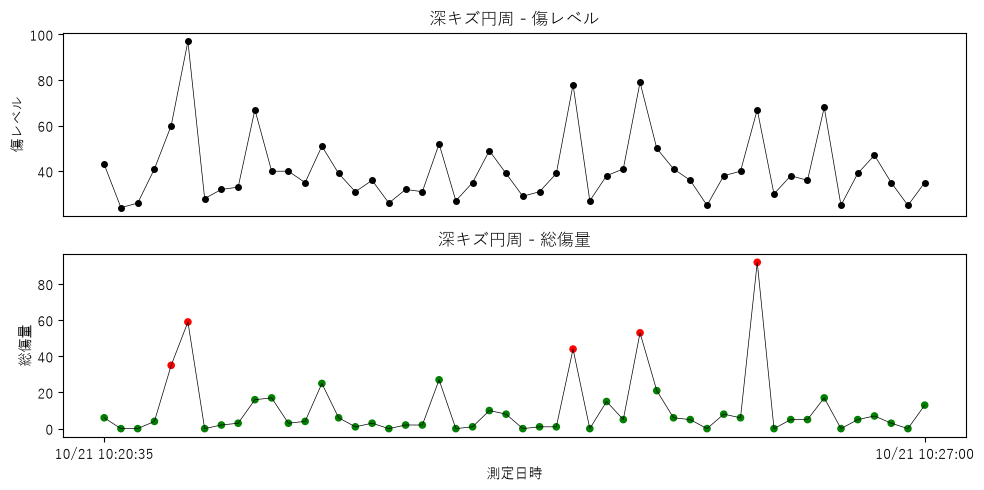

In [146]:
df_fukakizu_circ = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME),
    ["measured_at", "fukakizu_circ_level", "fukakizu_circ_volume", "fukakizu_circ_jg"],
].sort_values("measured_at")

create_level_volume_graph(df_fukakizu_circ, "fukakizu_circ", "深キズ円周")

---
### 2. 深キズXY 傷レベル＆総傷量

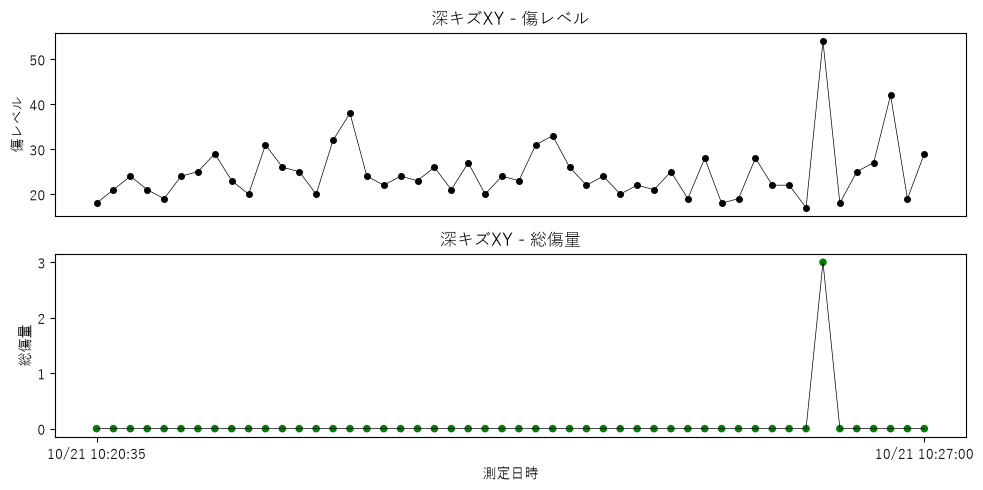

In [147]:
df_fukakizu_xy = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME),
    ["measured_at", "fukakizu_xy_level", "fukakizu_xy_volume", "fukakizu_xy_jg"],
].sort_values("measured_at")

create_level_volume_graph(df_fukakizu_xy, "fukakizu_xy", "深キズXY")

---
### 3. 浅キズ円周 傷レベル＆総傷量

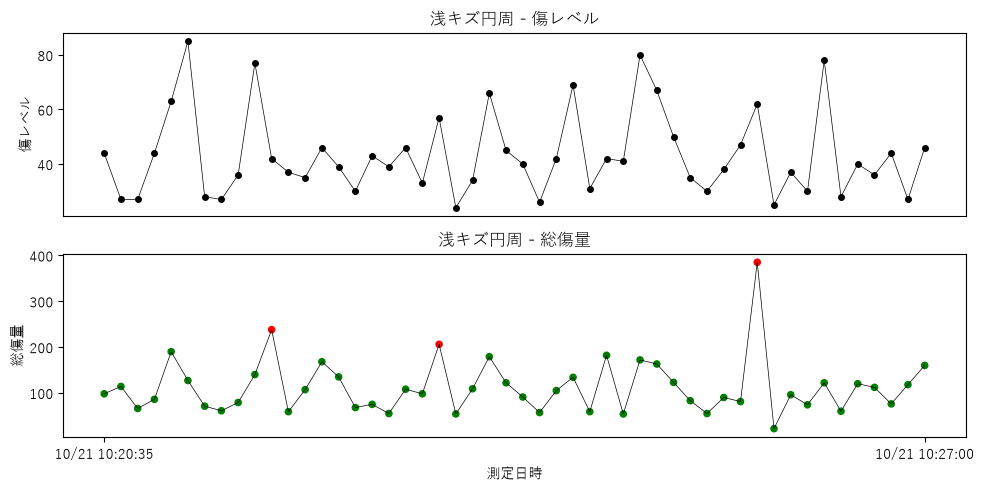

In [148]:
df_asakizu_circ = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME),
    ["measured_at", "asakizu_circ_level", "asakizu_circ_volume", "asakizu_circ_jg"],
].sort_values("measured_at")

create_level_volume_graph(df_asakizu_circ, "asakizu_circ", "浅キズ円周")

---
### 4. 浅キズXY 傷レベル＆総傷量

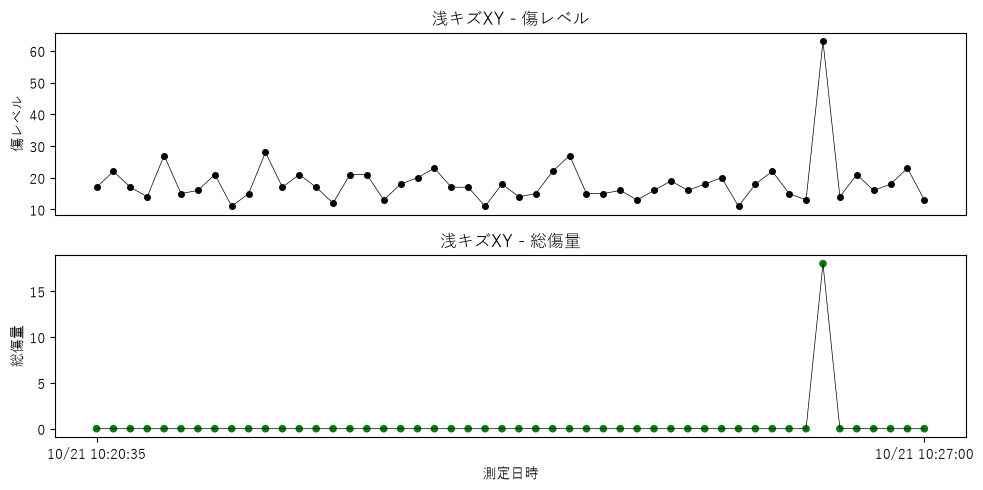

In [149]:
df_asakizu_xy = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME),
    ["measured_at", "asakizu_xy_level", "asakizu_xy_volume", "asakizu_xy_jg"],
].sort_values("measured_at")

create_level_volume_graph(df_asakizu_xy, "asakizu_xy", "浅キズXY")

In [150]:
# ---------------------------------------------
#  Functions
# ---------------------------------------------
def create_chamfer_graph(df, column_prefix, display_label):
    value_column = f"{column_prefix}_value"
    jg_column = f"{column_prefix}_jg"

    x = range(len(df))

    fig, ax = plt.subplots(
        figsize=(10, 2.5),
    )

    ax.plot(
        x,
        df[value_column],
        color="black",
        linewidth=0.5,
    )

    colors = df[jg_column].map({
        0: "green",
        1: "red",
    })

    ax.scatter(
        x,
        df[value_column],
        c=colors,
        s=20,
    )

    first_datetime = df["measured_at"].iloc[0]
    last_datetime = df["measured_at"].iloc[-1]

    ax.set_xticks(
        [0, len(df) - 1],
        [
            first_datetime.strftime("%m/%d %H:%M:%S"),
            last_datetime.strftime("%m/%d %H:%M:%S"),
        ],
    )

    ax.set_xlabel("測定日時")
    ax.set_ylabel("測定値")
    ax.set_title(display_label)

    plt.tight_layout()
    plt.show()



---
### 5. 面取り径

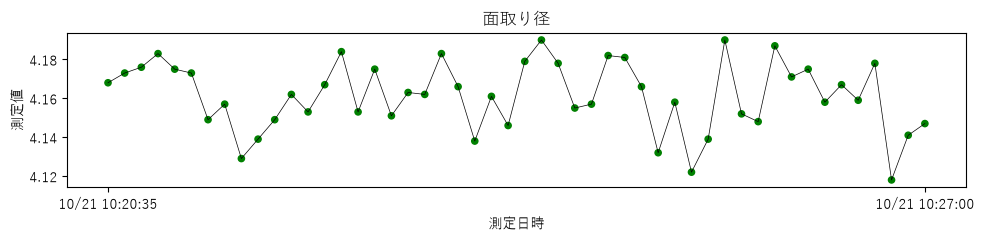

In [151]:
df_mentorikei = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME),
    [
        "measured_at",
        "mentorikei_value",
        "mentorikei_jg",
    ],
].sort_values("measured_at")

create_chamfer_graph(df_mentorikei, "mentorikei", "面取り径")

---
### 6. 面取り芯ズレ

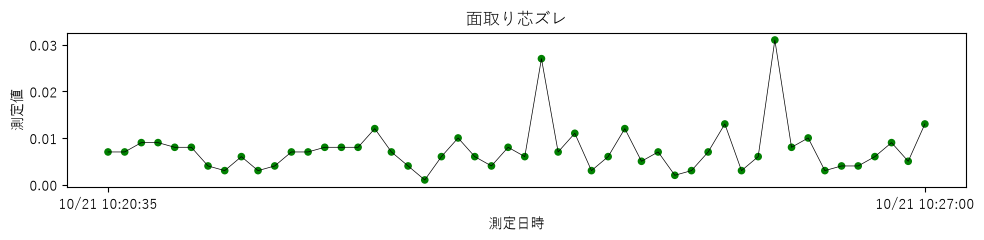

In [152]:
df_shinzure = df.loc[
    df["measured_at"].between(START_DATETIME, END_DATETIME),
    [
        "measured_at",
        "shinzure_value",
        "shinzure_jg",
    ],
].sort_values("measured_at")

create_chamfer_graph(df_shinzure, "shinzure", "面取り芯ズレ")